**1. Importing libraries and dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("winequality-red.csv", sep=",")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Dataset shape: (1599, 12)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.

**2.Load and inspect the dataset**

In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (1599, 12)

Column Names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicate Rows: 240

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        15

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


**3. Analyzing Wine Quality Distribution**

Wine Quality Distribution:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


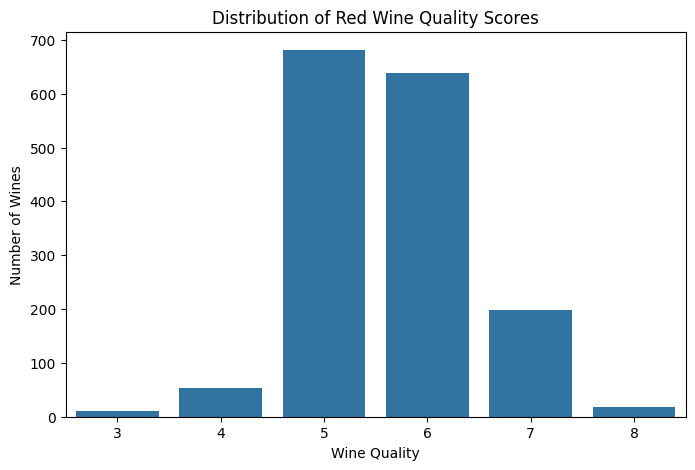

In [3]:
print("Wine Quality Distribution:")
print(df["quality"].value_counts().sort_index())

# Visualize the distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality")
plt.title("Distribution of Red Wine Quality Scores")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Wines")
plt.show()

**4. Exploring Chemical Features**

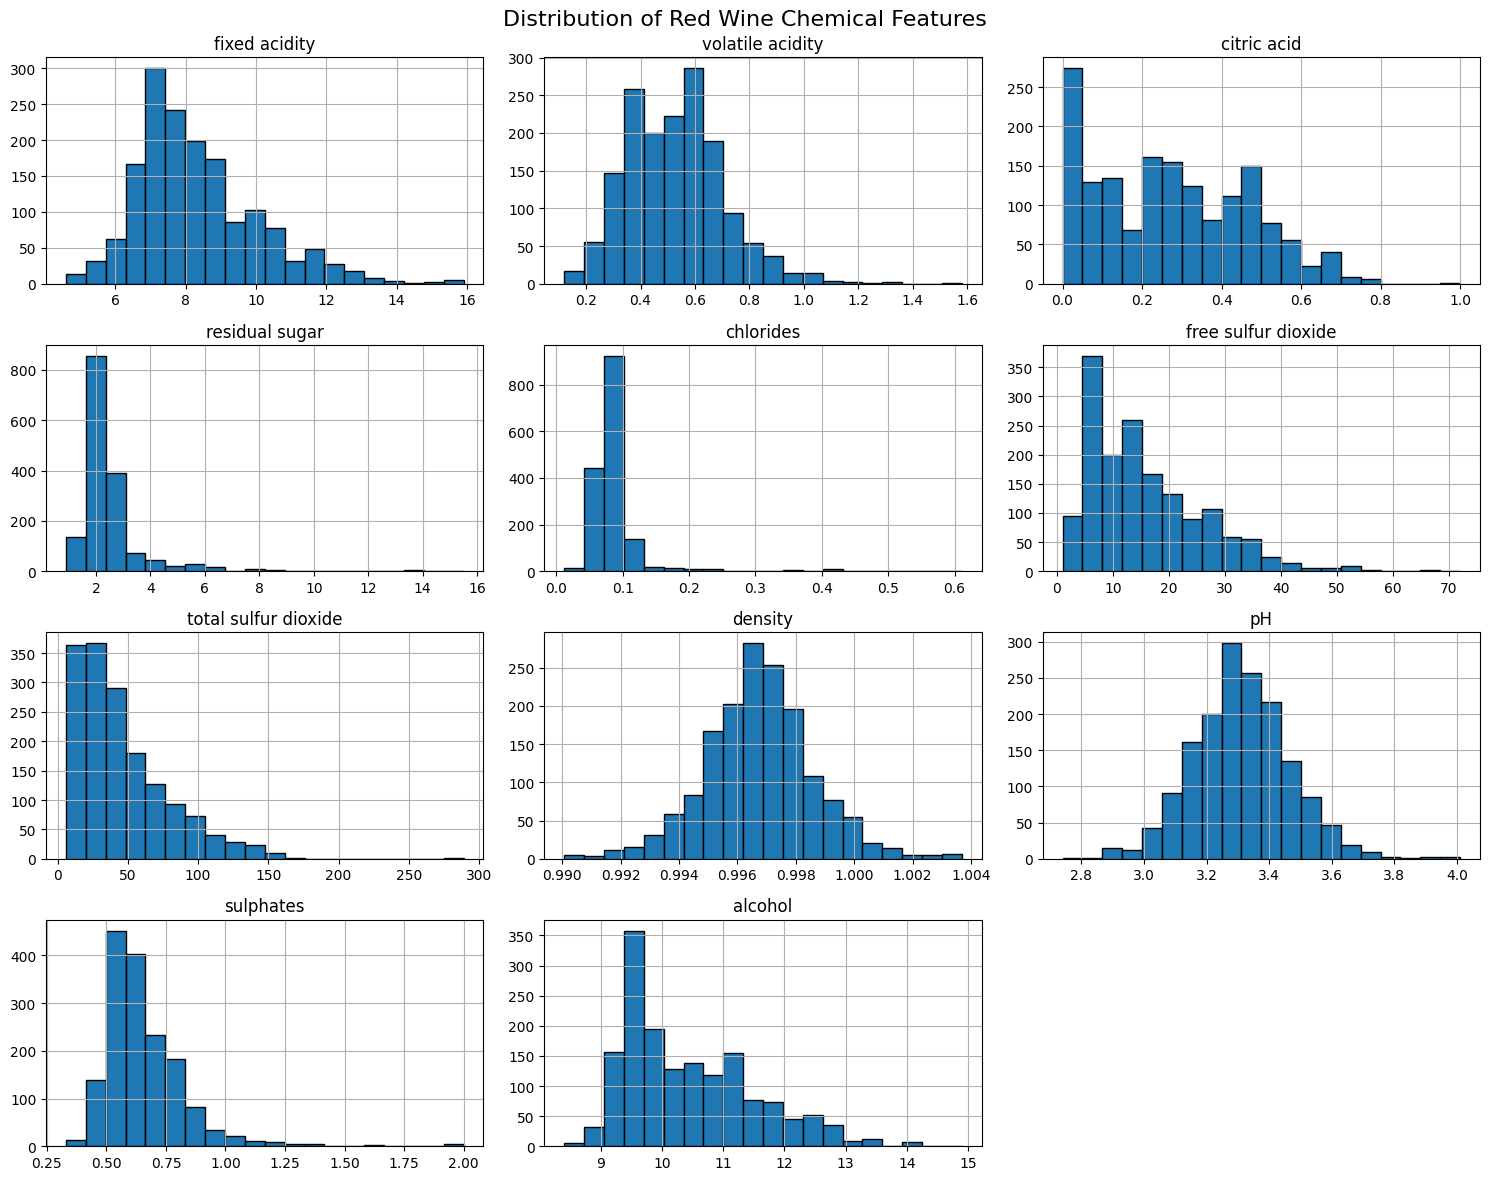

In [4]:
# Plot distributions of all chemical features
df.drop(columns=["quality"]).hist(
    figsize=(15, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Red Wine Chemical Features", fontsize=16)
plt.tight_layout()
plt.show()

**5. Creating a Correlation Heatmap**

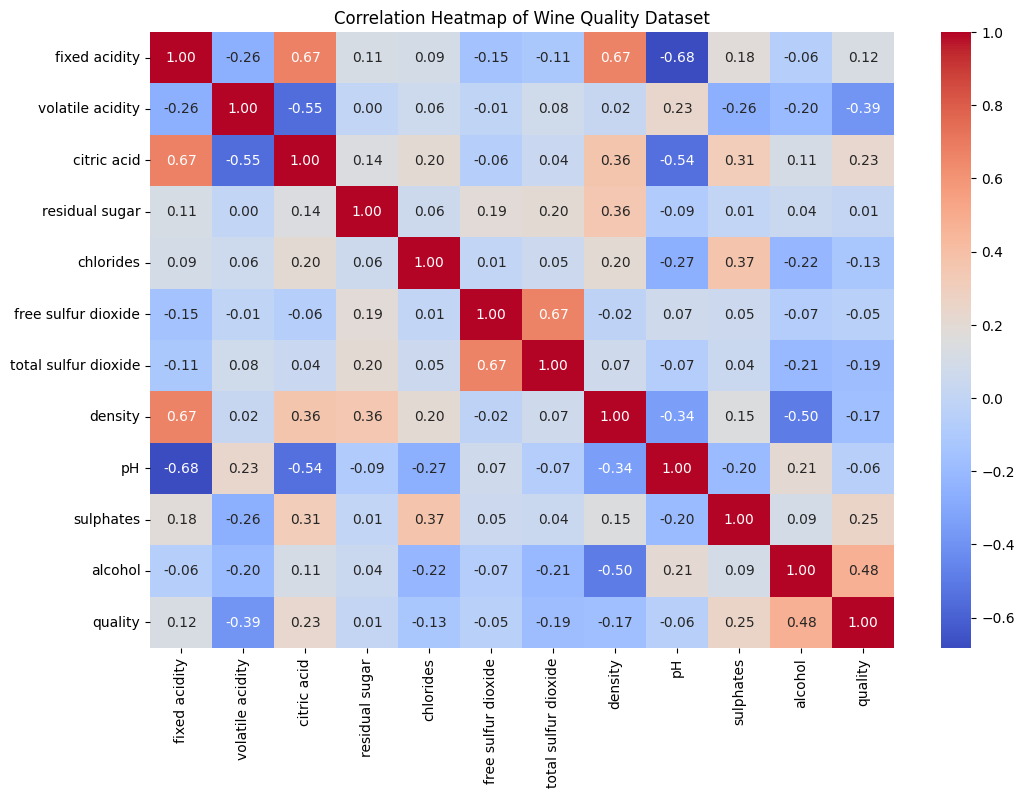

In [5]:
# Calculating correlation between numerical features
correlation = df.corr()

# Plot the correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Wine Quality Dataset")
plt.show()

**6. Handling Class Imbalance and Creating Quality Categories.**

Wine Quality Category Distribution:
quality_category
Low       744
Medium    638
High      217
Name: count, dtype: int64


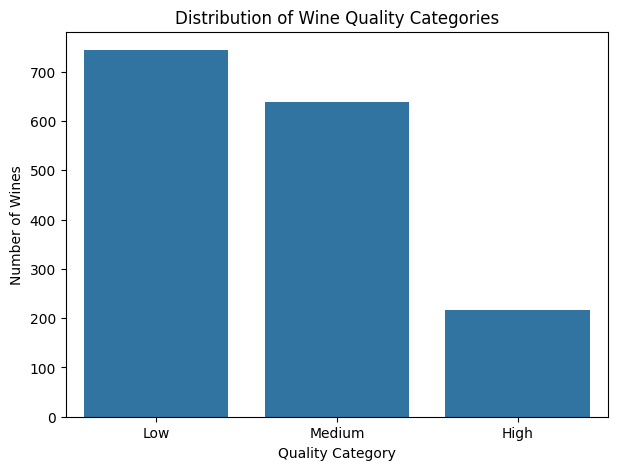

In [6]:
# Convert quality scores into three categories
def categorize_quality(quality):
    if quality <= 5:
        return "Low"
    elif quality == 6:
        return "Medium"
    else:
        return "High"

df["quality_category"] = df["quality"].apply(categorize_quality)

# Check category distribution
print("Wine Quality Category Distribution:")
print(df["quality_category"].value_counts())

# Visualize the categories
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="quality_category", order=["Low", "Medium", "High"])
plt.title("Distribution of Wine Quality Categories")
plt.xlabel("Quality Category")
plt.ylabel("Number of Wines")
plt.show()

**7. Preparing Features and Target**

In [7]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["quality", "quality_category"])
y = df["quality_category"]

# Split data while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (1279, 11)
Testing data shape: (320, 11)

Training target distribution:
quality_category
Low       595
Medium    510
High      174
Name: count, dtype: int64

Testing target distribution:
quality_category
Low       149
Medium    128
High       43
Name: count, dtype: int64


**8. Random forest model**

In [8]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


**9.SGD Classifier**

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier

# Create a pipeline that scales features and trains the SGD model
sgd_model = make_pipeline(
    StandardScaler(),
    SGDClassifier(random_state=42, class_weight="balanced", max_iter=1000, tol=1e-3)
)

# Train the model
sgd_model.fit(X_train, y_train)

print("SGD Classifier trained successfully!")

SGD Classifier trained successfully!


**10. SVC ModeL**

In [10]:
from sklearn.svm import SVC

# Create a pipeline that scales features and trains the SVC model
svc_model = make_pipeline(
    StandardScaler(),
    SVC(class_weight="balanced")
)

# Train the model
svc_model.fit(X_train, y_train)

print("SVC model trained successfully!")

SVC model trained successfully!


**11. All three Model**

In [11]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Store the trained models
models = {
    "Random Forest": rf_model,
    "SGD Classifier": sgd_model,
    "SVC": svc_model
}

# Evaluate each model
for name, model in models.items():
    y_pred = model.predict(X_test)

    print(f"\n{'=' * 50}")
    print(f"Model: {name}")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred, labels=["Low", "Medium", "High"]))


Model: Random Forest
Accuracy: 0.7500

Classification Report:
              precision    recall  f1-score   support

        High       0.68      0.60      0.64        43
         Low       0.80      0.82      0.81       149
      Medium       0.71      0.72      0.71       128

    accuracy                           0.75       320
   macro avg       0.73      0.71      0.72       320
weighted avg       0.75      0.75      0.75       320

Confusion Matrix:
[[122  25   2]
 [ 26  92  10]
 [  4  13  26]]

Model: SGD Classifier
Accuracy: 0.5531

Classification Report:
              precision    recall  f1-score   support

        High       0.23      0.33      0.27        43
         Low       0.70      0.74      0.72       149
      Medium       0.51      0.41      0.45       128

    accuracy                           0.55       320
   macro avg       0.48      0.49      0.48       320
weighted avg       0.56      0.55      0.55       320

Confusion Matrix:
[[111  24  14]
 [ 43  52  33]

**12. Feature Importance for RFM**

                 Feature  Importance
10               alcohol    0.167555
9              sulphates    0.113484
1       volatile acidity    0.112883
6   total sulfur dioxide    0.091311
2            citric acid    0.086697
7                density    0.085455
4              chlorides    0.077911
0          fixed acidity    0.069365
8                     pH    0.068741
3         residual sugar    0.064081
5    free sulfur dioxide    0.062517


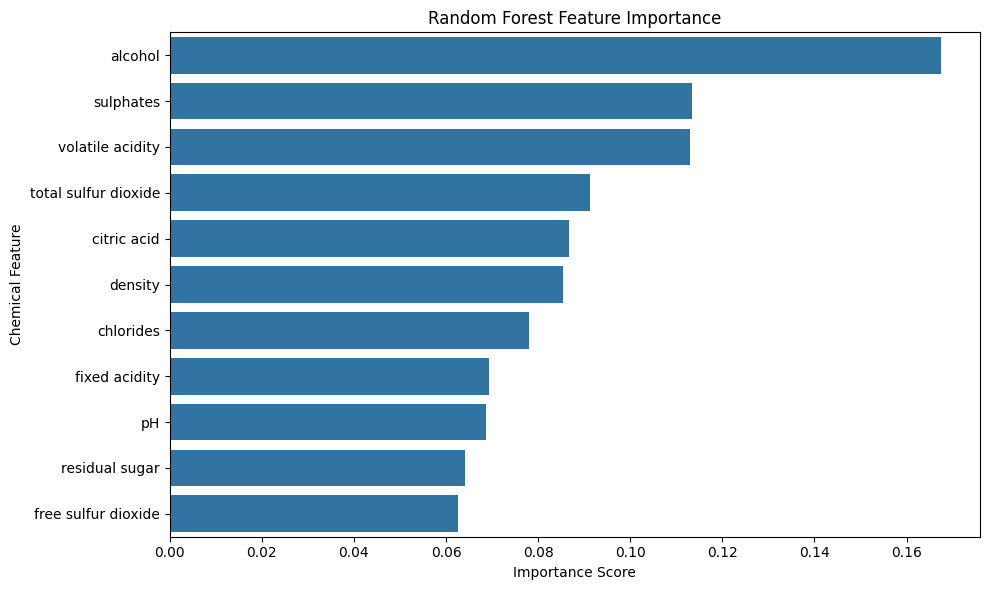

In [13]:
# Get feature importance from Random Forest
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sorting features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Chemical Feature")
plt.tight_layout()
plt.show()

**13. Model Comparison table**

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Compare model performance
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values(by="F1-Score", ascending=False)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.7500,0.7487,0.7500,0.7490
2,SVC,0.6094,0.6214,0.6094,0.6041
1,SGD Classifier,0.5531,0.5639,0.5531,0.5545


## Conclusion

In this project, Exploratory Data Analysis (EDA) was conducted on the Red Wine Quality dataset to find the distribution of wine quality ratings and the correlations among the chemical properties.

The quality ratings were categorized into three groups: low, medium, and high. Random Forest, SGD Classifier, and Support Vector Classifier (SVC) were tested as three types of machine learning models. Accuracy, precision, recall, and F1-score were calculated for evaluation of those three models.

The Random Forest feature importance plot was used to find the chemical properties that have the most effect on the predictions by this model.

From the result of model comparison, **the best model is chosen based on its highest weighted F1-score**.

This project is a good example of how data analysis and machine learning can help in classifying the categories of wine qualities from chemical properties.